# 3B karaciger VAE — yerel egitim (RTX 3080 Ti)

Bu notebook 3B sekil-VAE'sini **kendi GPU'nda** egitir. Sira:
1. Ortam kontrolu (dogru cekirdek + CUDA)
2. Smoke precompute (32^3, val split — hizli)
3. Smoke egitim (32^3, birkac epoch — 'calisiyor mu?')
4. Tam egitim (64^3, early-stopping)
5. Sonuc ozeti

> Hucreleri **sirayla** calistir. Yeni kod yok — hepsi `scripts/` altindaki
> mevcut `precompute_volumes.py` ve `train_vae3d.py`'yi cagirir.

## Hucre 1 — Ortam kontrolu

En kritik kontrol: **dogru cekirdek secili mi?** Sistemde iki Python var —
PATH'teki duz `python` CPU-only, CUDA yalnizca **sam2** conda ortaminda.
Asagidaki hucre `sys.executable`'i yazdirir; CUDA gorunmuyorsa buyuk bir
uyari basar -> o zaman **Kernel menusunden sam2 cekirdegini sec** ve tekrar
calistir.

In [6]:
import os, sys
from pathlib import Path

import torch

# --- Proje kokunu bul: notebook notebooks/ altindaysa bir ust dizine cik ---
here = Path.cwd()
project_root = here.parent if here.name == "notebooks" else here
os.chdir(project_root)
sys.path.insert(0, str(project_root))
print("proje koku :", project_root)
assert (project_root / "scripts" / "train_vae3d.py").exists(), \
    "train_vae3d.py bulunamadi — notebook proje kokunden veya notebooks/ altindan acilmali"

# --- Dogru cekirdek + CUDA guvenlik kontrolu ---
print("python     :", sys.executable)   # 'sam2' gecmeli
print("torch      :", torch.__version__)
cuda_ok = torch.cuda.is_available()
print("CUDA var mi:", cuda_ok)
if cuda_ok:
    print("GPU        :", torch.cuda.get_device_name(0))
    total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"GPU bellek : {total_gb:.1f} GB")
else:
    print("\n" + "!" * 68)
    print("!! UYARI: CUDA GORUNMUYOR — buyuk olasilikla YANLIS CEKIRDEK secili.")
    print("!! Yukaridaki 'python' yolu 'sam2' icermeli. Icermiyorsa:")
    print("!!   Kernel menusu -> sam2 conda ortaminin cekirdegini sec -> bu")
    print("!!   hucreyi tekrar calistir. CPU'da egitim cok yavas olur.")
    print("!" * 68)

proje koku : c:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
python     : c:\Users\ahmet.yaylalioglu\.conda\envs\sam2\python.exe
torch      : 2.7.1+cu118
CUDA var mi: True
GPU        : NVIDIA GeForce RTX 3080 Ti Laptop GPU
GPU bellek : 16.0 GB


## Hucre 2 — Smoke precompute (32^3, val split)

Hizli saglik kontrolu: sadece **val** split'ini 32^3'te NIfTI'den `.npz`'ye
cevirir (48 hasta, hizli). Script doluluk (occupancy) dagilimini ve NIfTI
parity sonucunu loglar — cok dusuk doluluk (<%1) organin resize'da eridigini
gosterirdi.

In [7]:
import subprocess, sys

# Sadece val split, 32^3 (config varsayilani). --no-verify KOYMUYORUZ ki
# parity de gorunsun. sys.executable ile CALISAN cekirdegin python'unu
# kullaniriz (yanlis PATH python'una dusme riski yok).
cmd = [sys.executable, "scripts/precompute_volumes.py",
       "--config", "configs/vae3d.yaml", "--splits", "val"]
print(">", " ".join(cmd), "\n")
subprocess.run(cmd, check=True)

> c:\Users\ahmet.yaylalioglu\.conda\envs\sam2\python.exe scripts/precompute_volumes.py --config configs/vae3d.yaml --splits val 



CompletedProcess(args=['c:\\Users\\ahmet.yaylalioglu\\.conda\\envs\\sam2\\python.exe', 'scripts/precompute_volumes.py', '--config', 'configs/vae3d.yaml', '--splits', 'val'], returncode=0)

## Hucre 3 — Smoke egitim (32^3, az hasta + az epoch)

Gercek hizli smoke: `train_vae3d.py`'yi 32^3 + `--limit 20` (20 hasta) + `--epochs 6`
ile calistirir, ~2-3 dakikada biter. Amac sadece **loss dusuyor mu, cokuyor mu**
gormek — kodun ucundan ucuna calistigini dogrulamak. Bittiginde egitim egrisi ve
reconstruction onizlemesini (3 ortogonal kesit) notebook icine basar.

> **DIKKAT — bu sonuclar temsili DEGIL.** 20 hastalik egitimin val Dice'i ve
> overfit yoklugu az veriyle **aldaticidir**; tam performans olarak yorumlama.
> Gercek sonuc Hucre 4'te (tum 222 hasta, tam epoch, early-stopping).

> c:\Users\ahmet.yaylalioglu\.conda\envs\sam2\python.exe -u scripts/train_vae3d.py --config configs/vae3d.yaml --limit 20 --epochs 6 

2026-08-09 18:21:03,507 INFO train: device: cuda (NVIDIA GeForce RTX 3080 Ti Laptop GPU)
2026-08-09 18:21:03,580 INFO data.raos_volume: RAOSVolumes(group=train, split=train): 222 volumes (patients)
2026-08-09 18:21:03,654 INFO data.raos_volume: RAOSVolumes(group=train, split=val): 48 volumes (patients)
2026-08-09 18:21:03,657 INFO train_vae3d: train volumes: 20 | val volumes: 20
2026-08-09 18:21:03,763 INFO train_vae3d: ConvVAE3D: 1577121 params | ~7.7 MB/forward (b=8)
2026-08-09 18:21:05,573 INFO train_vae3d: run tag=vae3d_latent64 | epochs=6 early_stop_patience=15 min_delta=0.001
2026-08-09 18:21:17,401 INFO train_vae3d: epoch 1/6 | 12s | train=1.5936 val=1.4310 | val_dice=0.3259 blur=0.4841 | gap=+0.1626 | best=0.3259 @ep1
2026-08-09 18:21:29,683 INFO train_vae3d: epoch 2/6 | 12s | train=1.5434 val=1.4303 | val_dice=0.3259 blur=0.4860 | gap=+0.1131 |

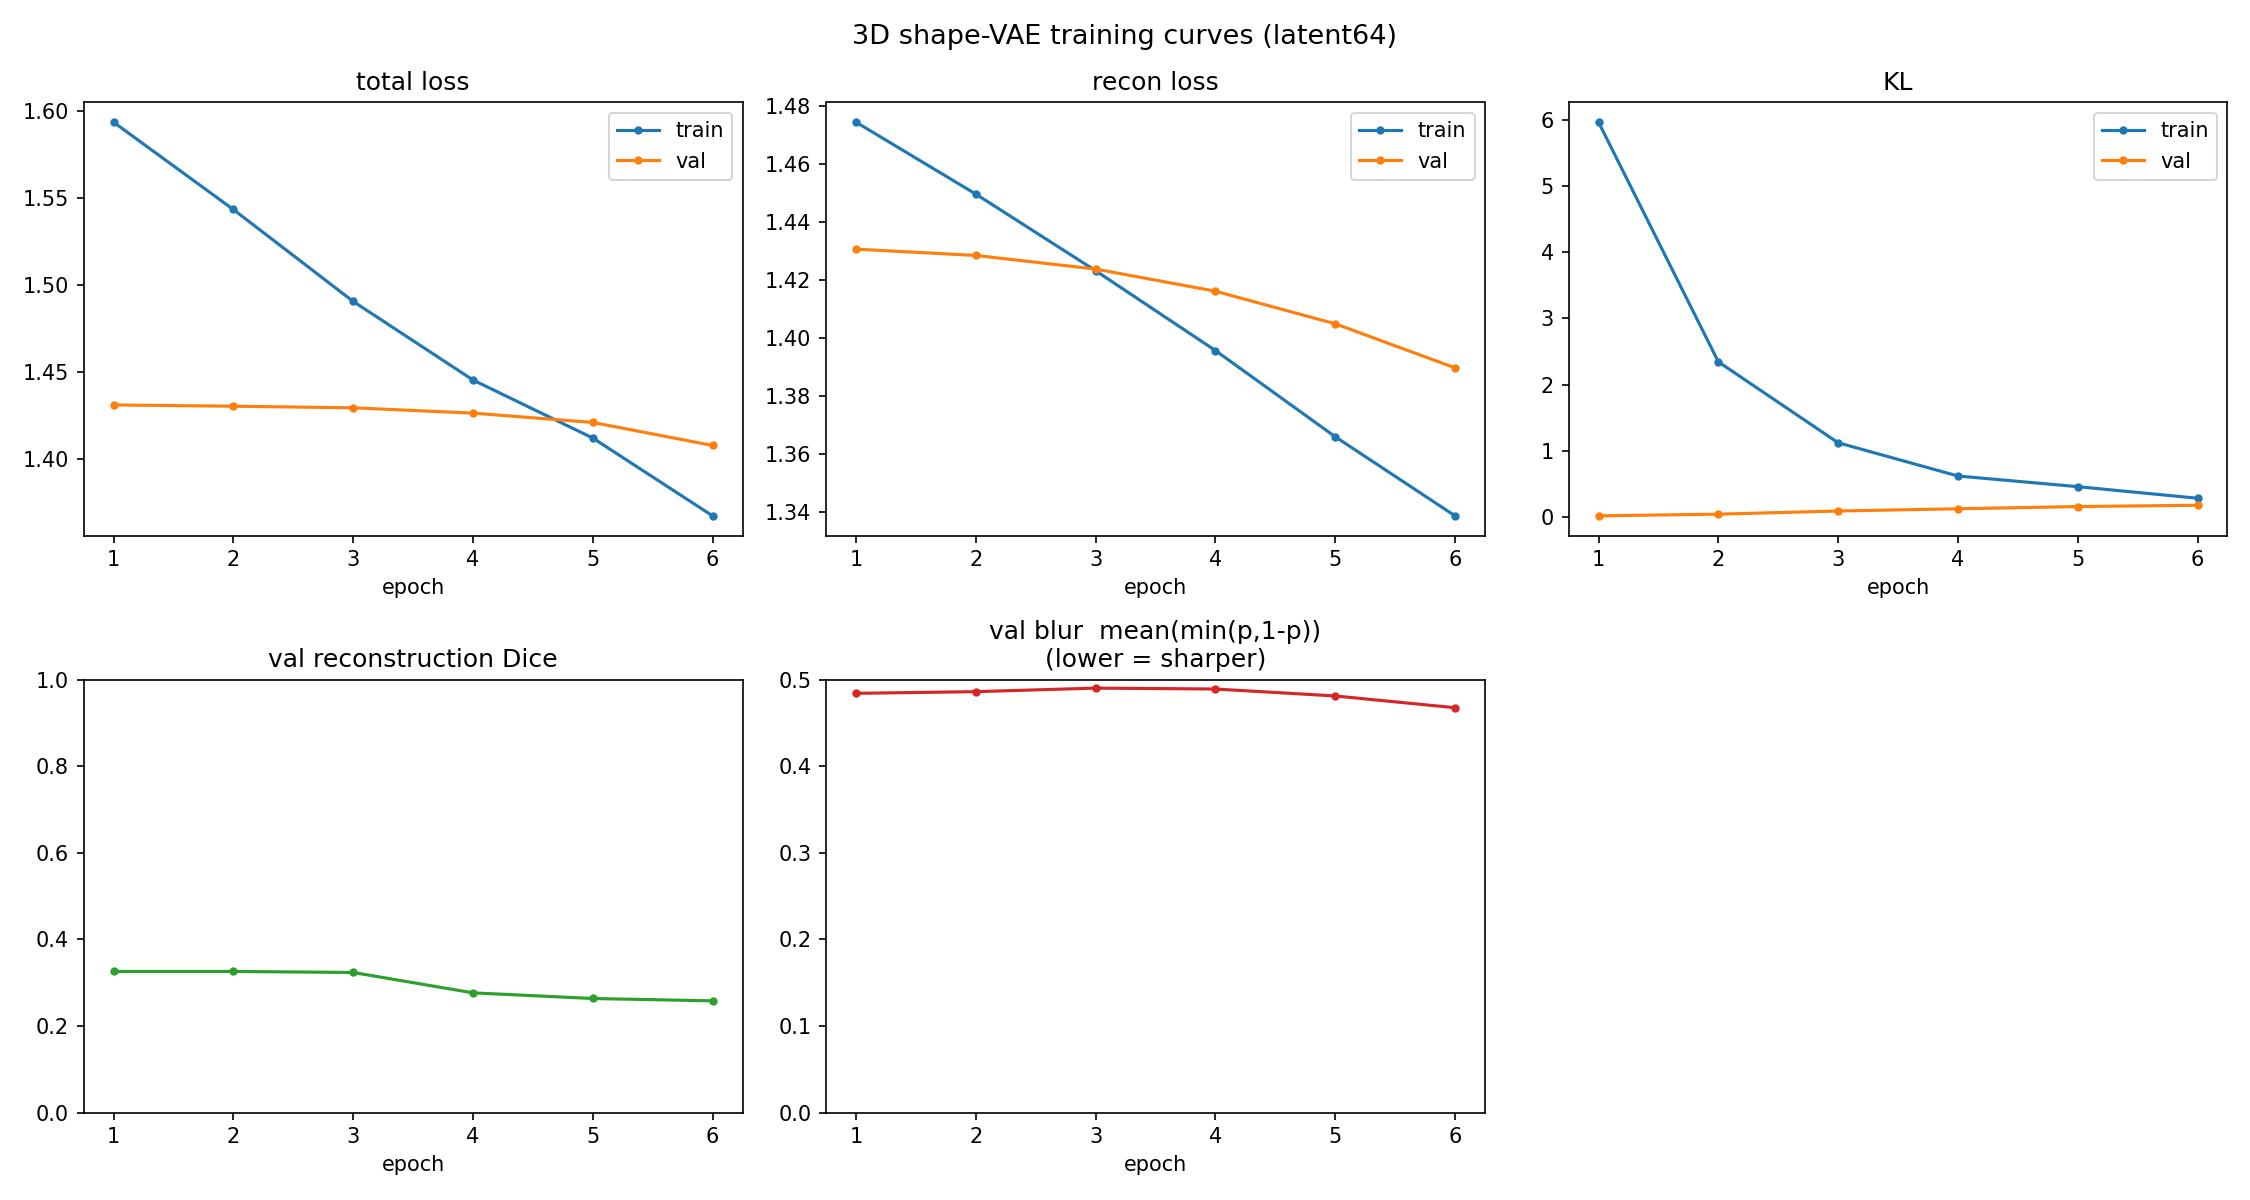

outputs\vae3d_recon_epoch_5_latent64.png


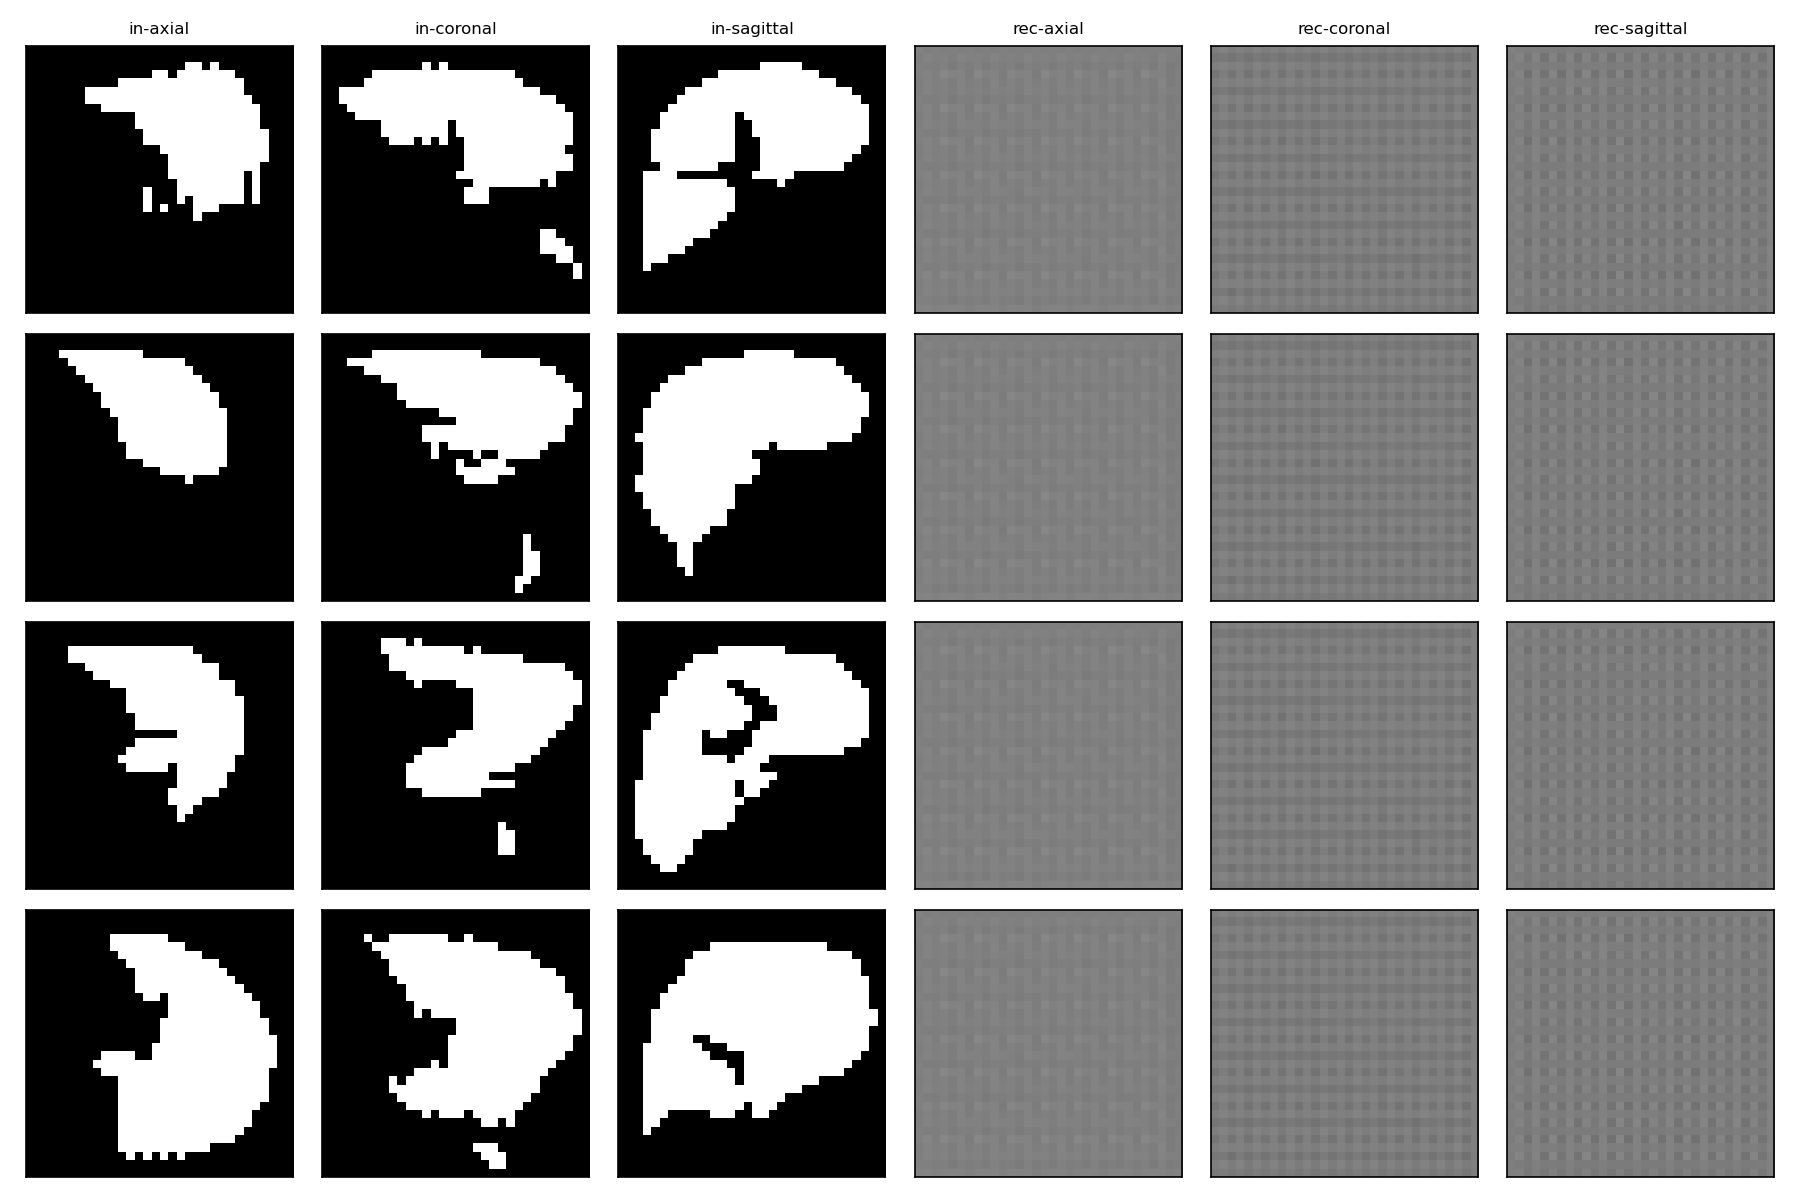

In [8]:
import subprocess, sys
from pathlib import Path
from IPython.display import Image, display

def run_streamed(cmd):
    """Alt sureci calistir ve stdout'unu SATIR SATIR anlik bas (tamponsuz)."""
    cmd = [cmd[0], "-u"] + cmd[1:]
    print(">", " ".join(cmd), "\n", flush=True)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError(f"komut basarisiz (returncode={proc.returncode})")

# Gercek hizli smoke: az hasta (--limit 20) VE az epoch (--epochs 6) -> ~2-3 dk.
# Amac sadece "kod calisiyor mu, loss dusuyor mu". Config'teki 100 epoch DEGIL.
run_streamed([sys.executable, "scripts/train_vae3d.py",
              "--config", "configs/vae3d.yaml",
              "--limit", "20", "--epochs", "6"])

out = Path("outputs")
for png in sorted(out.glob("vae3d_training_curves_*.png")):
    print(png); display(Image(str(png)))
recon = sorted(out.glob("vae3d_recon_epoch_*_*.png"))
if recon:
    print(recon[-1]); display(Image(str(recon[-1])))

## Hucre 4 — Tam egitim (64^3)

**Uzun surer.** 64^3'e cikmak icin `_base_: vae3d.yaml`'i miras alip yalnizca
`input_size`'i ezen gecici bir config (`configs/vae3d_full.yaml`) yazilir —
cekirdek kod/config degismez. Sonra:
1. 64^3 precompute (tum splitler, `--limit` yok)
2. 64^3 tam egitim (epochs=100, early-stopping patience=15)

> - GPU'da uzun surebilir; **checkpoint her epoch** `outputs/checkpoints/`'a yazilir.
> - Kesilirse: asagidaki egitim satirina
>   `"--resume", "outputs/checkpoints/vae3d_last_latent64.pt"` ekleyip tekrar
>   calistir — kaldigi epoch'tan devam eder.
> - **Overfit izle:** loglardaki `gap=` (train - val total) buyur ve val recon
>   Dice dusmeye baslarsa 222 hacim az veri demektir -> augmentation gerekecek
>   (hook `train_vae3d.py`'de hazir, simdilik no-op).

yazildi: configs\vae3d_full.yaml
> c:\Users\ahmet.yaylalioglu\.conda\envs\sam2\python.exe -u scripts/precompute_volumes.py --config configs\vae3d_full.yaml 

2026-08-09 18:24:52,616 INFO precompute_volumes: === precomputing split: train ===
2026-08-09 18:24:52,689 INFO data.raos_volume: RAOSVolumes(group=train, split=train): 222 volumes (patients)
2026-08-09 18:24:52,967 INFO precompute_volumes:   train: 1/222 volumes
2026-08-09 18:24:53,098 INFO precompute_volumes:   train: 2/222 volumes
2026-08-09 18:24:53,190 INFO precompute_volumes:   train: 3/222 volumes
2026-08-09 18:24:53,270 INFO precompute_volumes:   train: 4/222 volumes
2026-08-09 18:24:53,488 INFO precompute_volumes:   train: 5/222 volumes
2026-08-09 18:24:53,590 INFO precompute_volumes:   train: 6/222 volumes
2026-08-09 18:24:53,783 INFO precompute_volumes:   train: 7/222 volumes
2026-08-09 18:24:53,882 INFO precompute_volumes:   train: 8/222 volumes
2026-08-09 18:24:53,973 INFO precompute_volumes:   train: 9/222 volumes
20

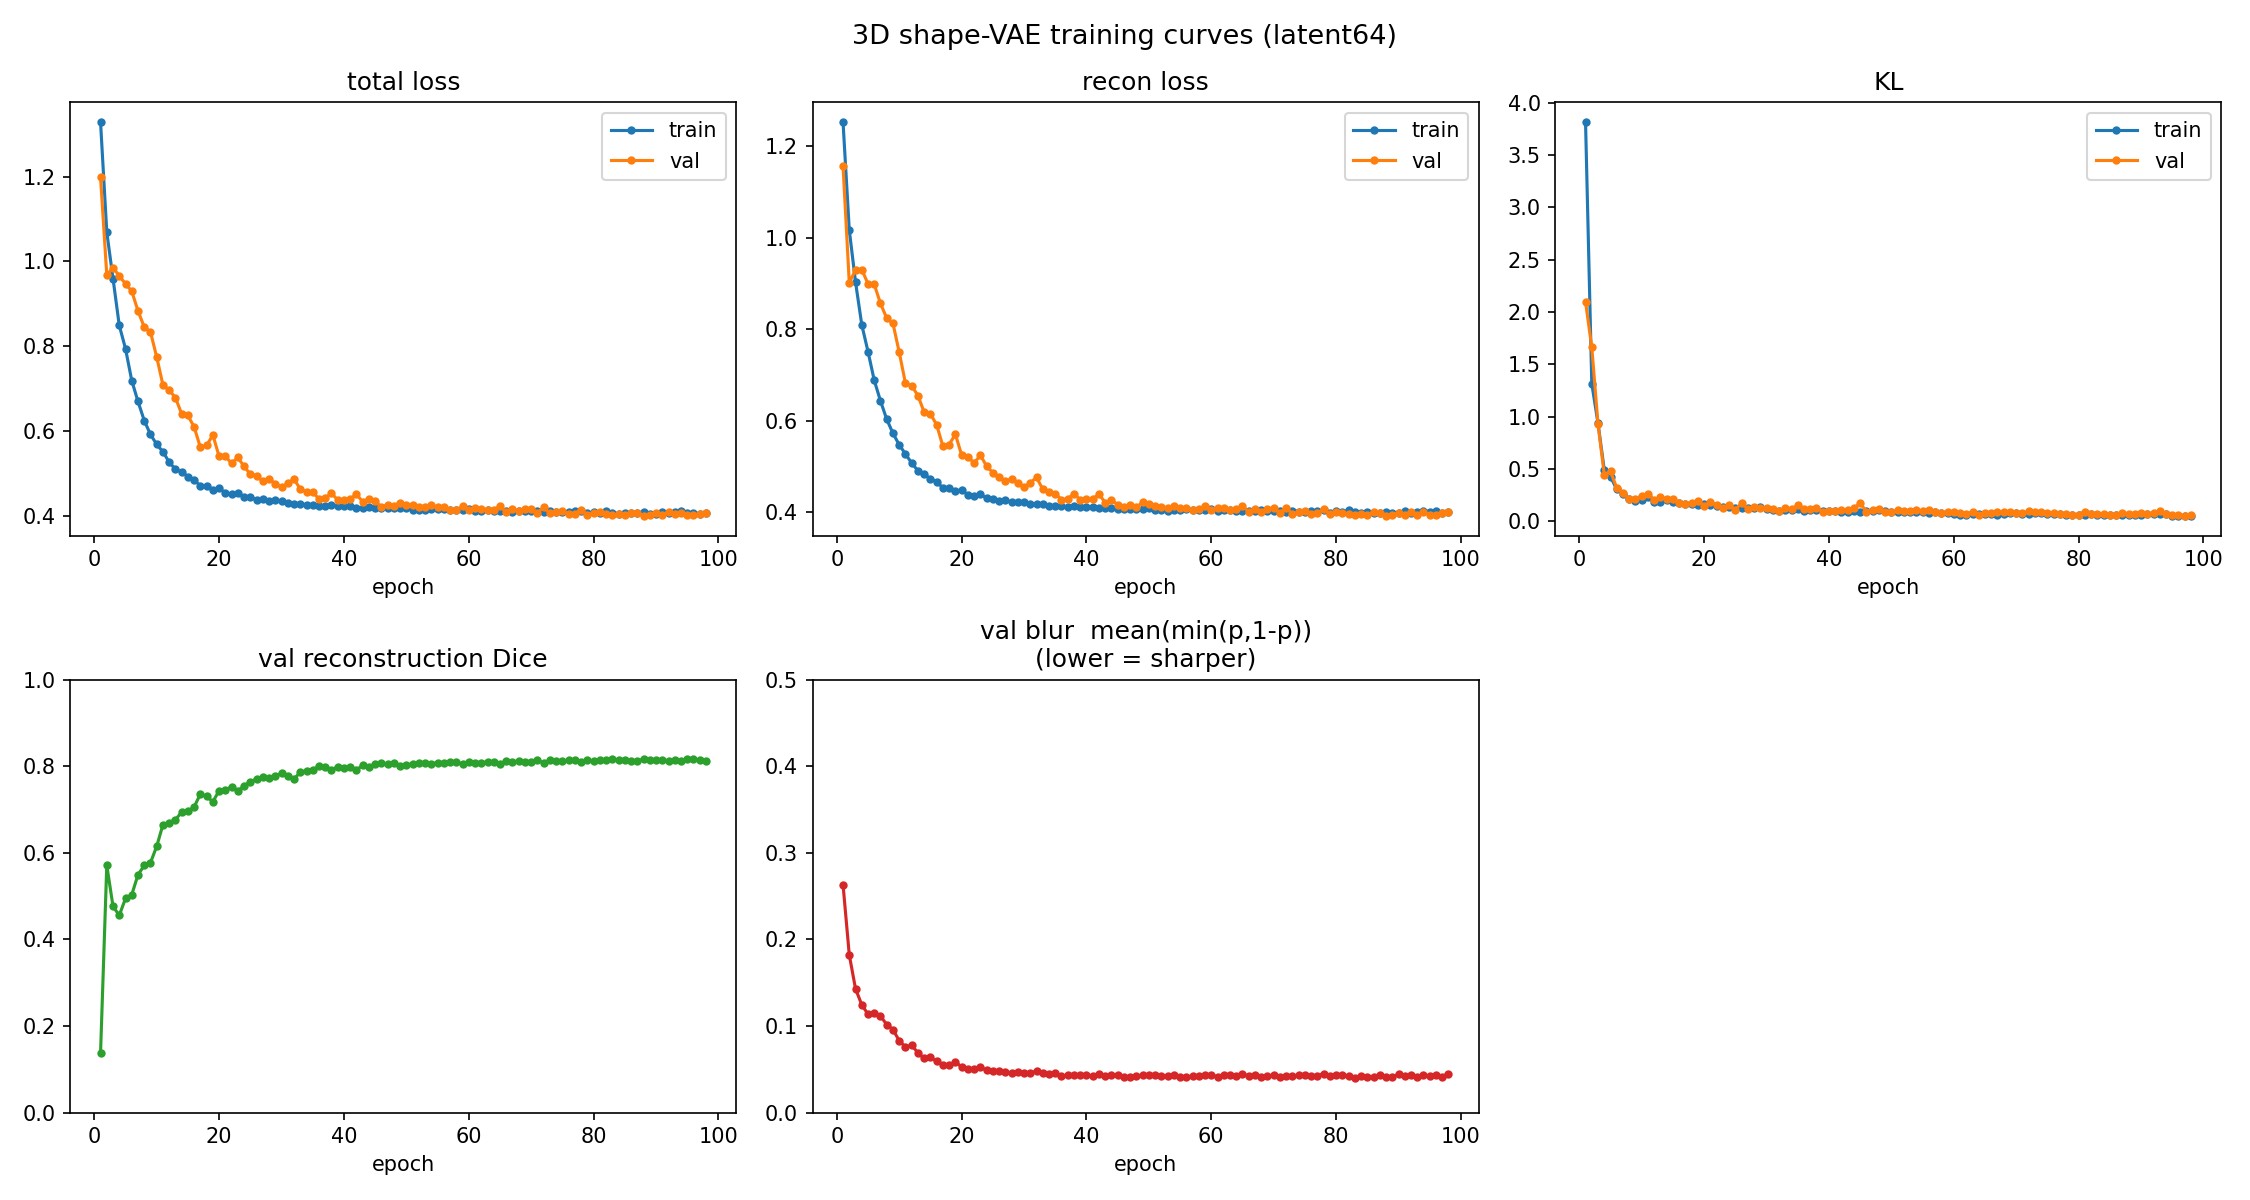

outputs\vae3d_recon_epoch_90_latent64.png


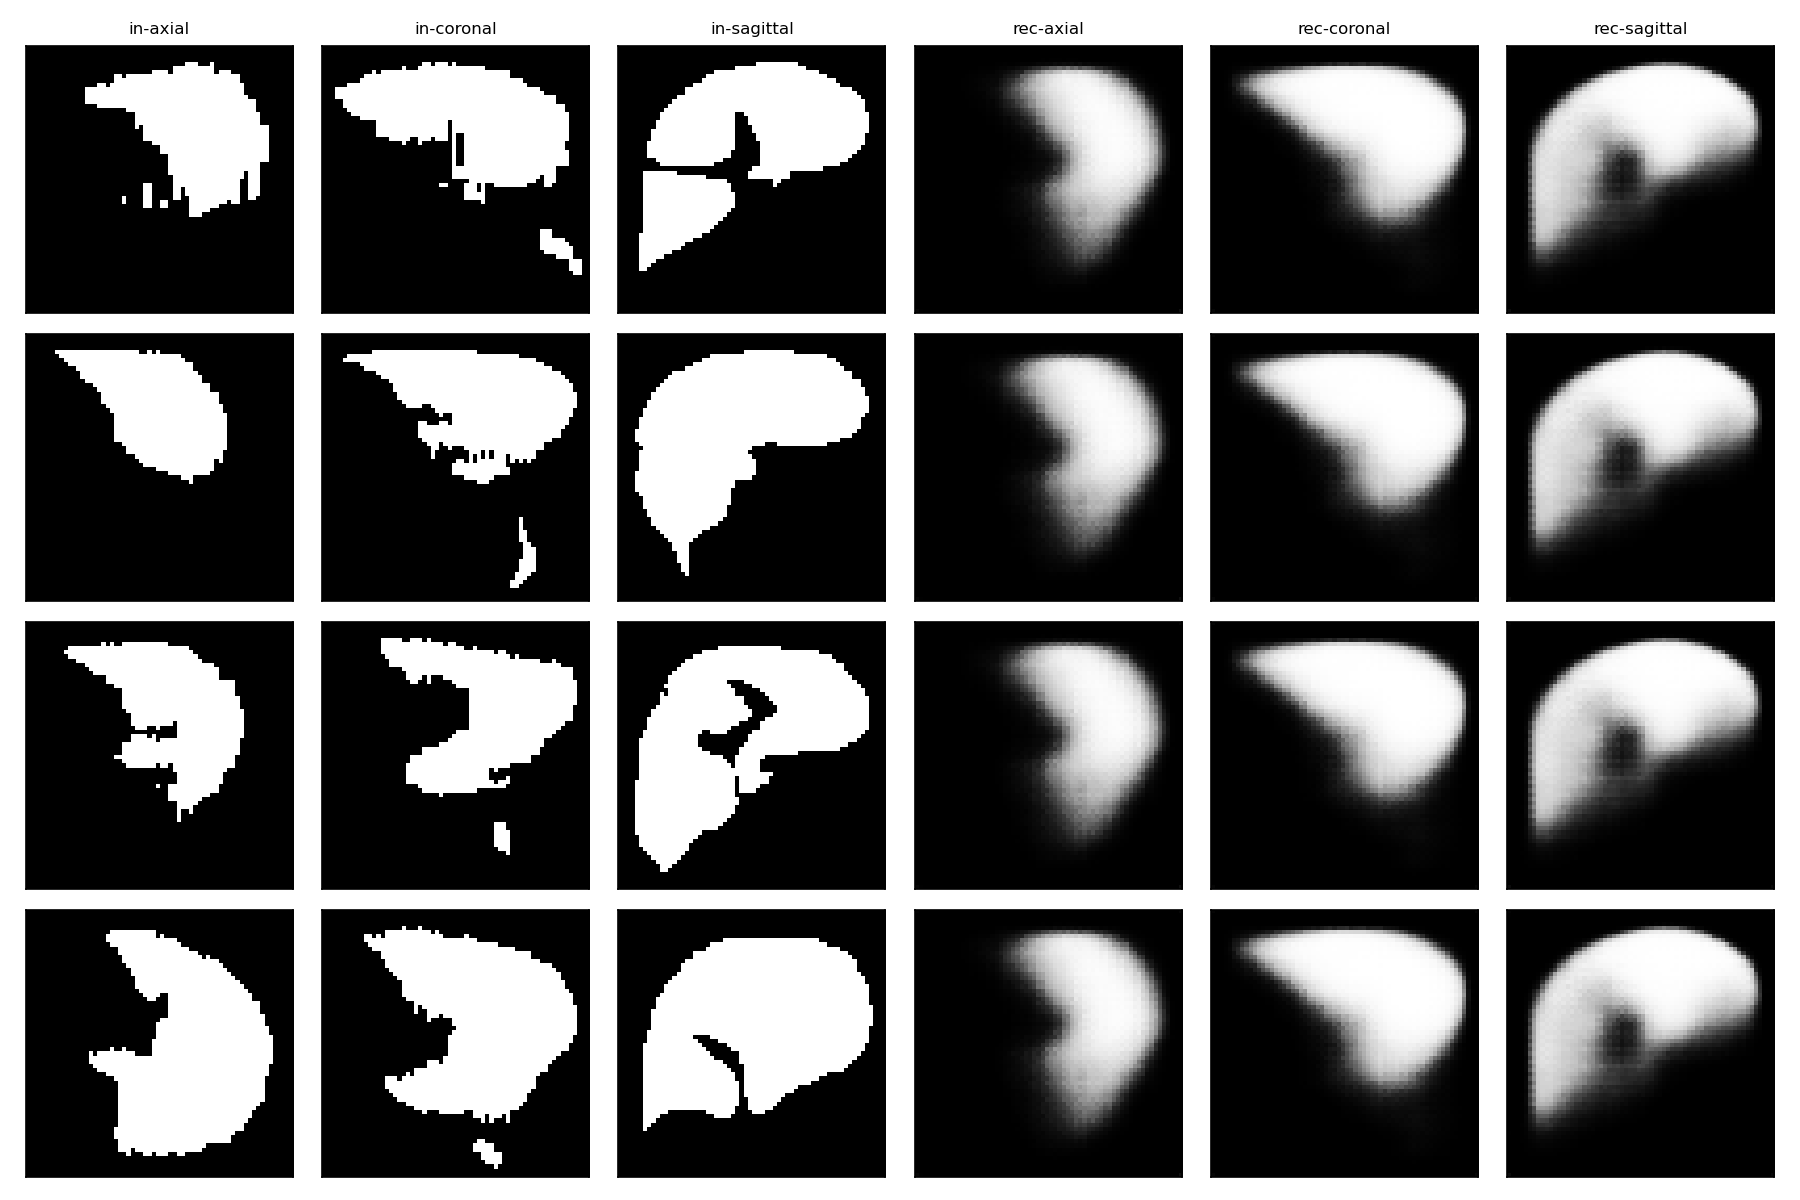

outputs\vae3d_recon_epoch_95_latent64.png


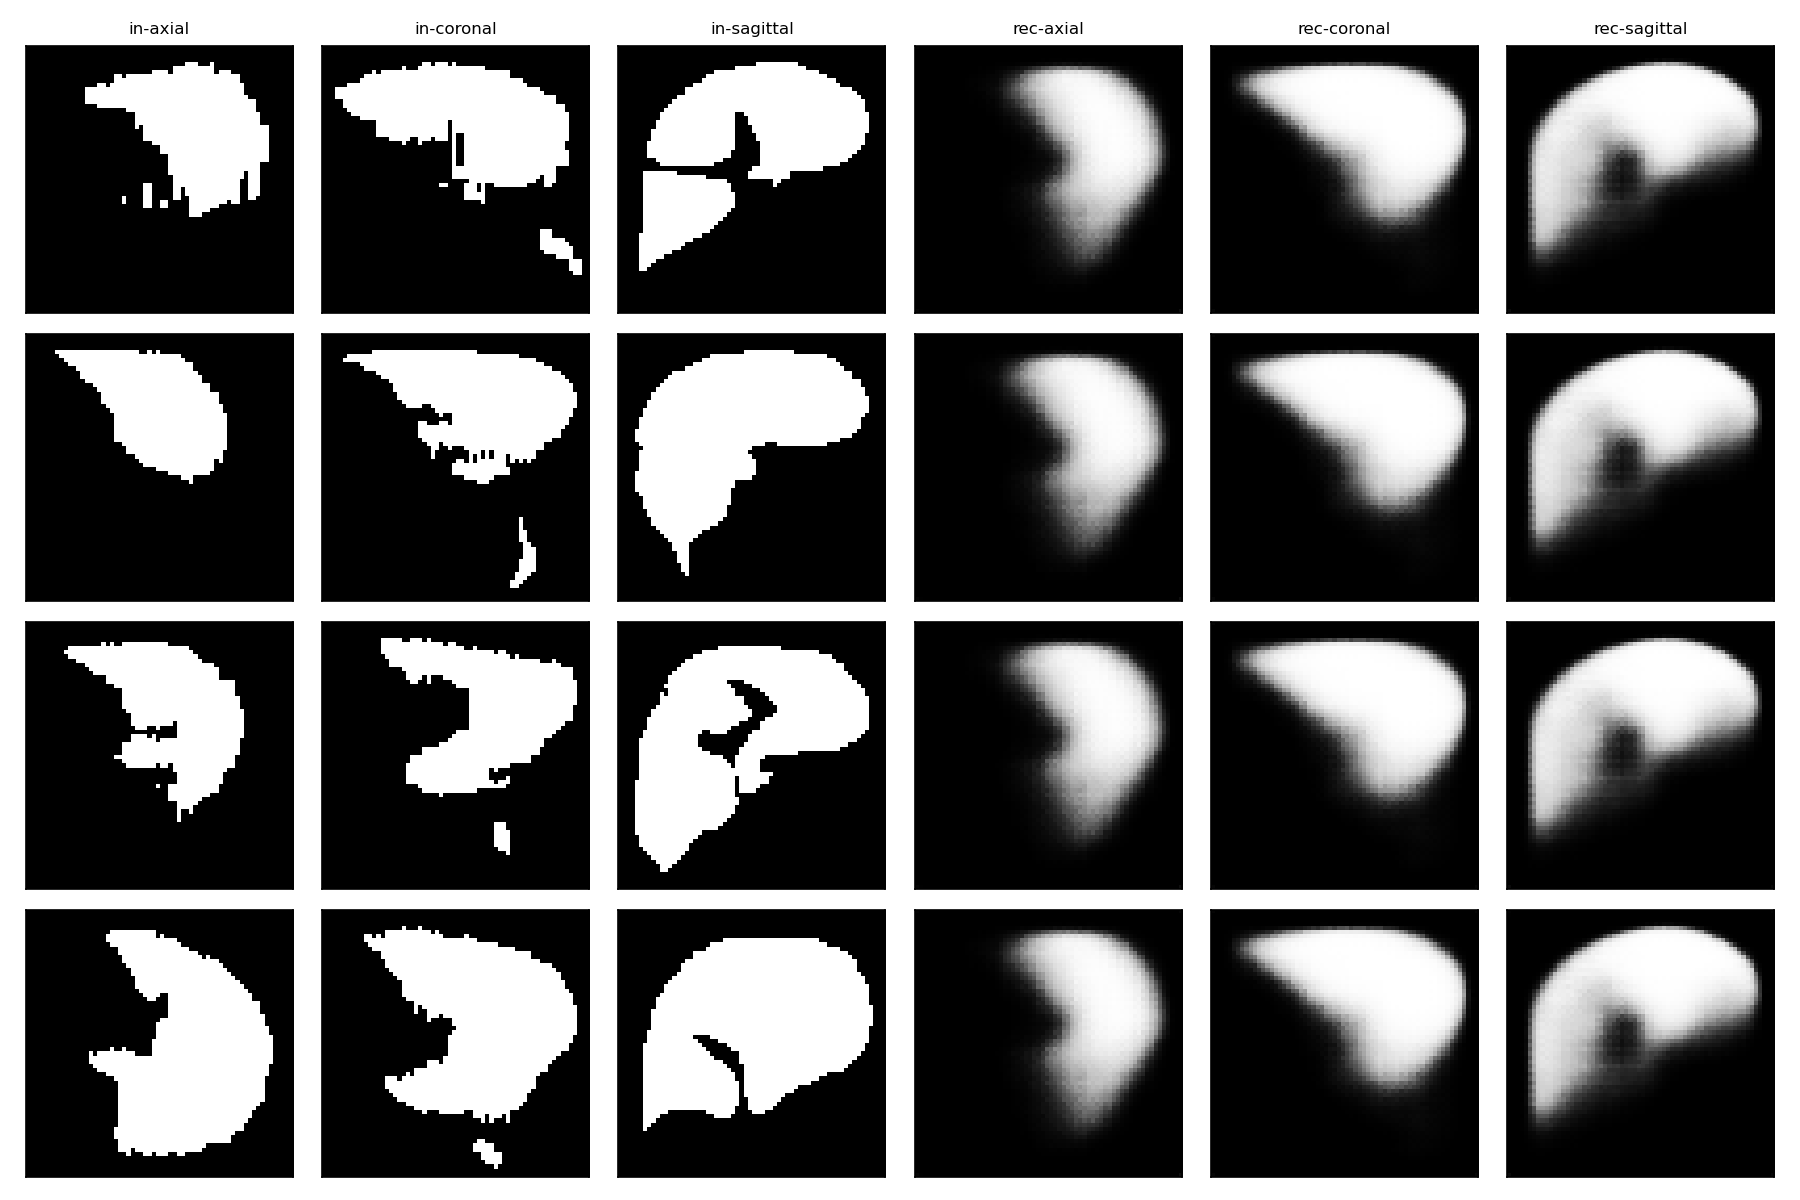

In [9]:
import subprocess, sys
from pathlib import Path
from IPython.display import Image, display

def run_streamed(cmd):
    """Alt sureci calistir ve stdout'unu SATIR SATIR anlik bas (tamponsuz).
    Python'u -u ile cagirir + stderr'i stdout'a birlestirir ki her epoch logu
    (logging stderr'e yazar) aninda gorunsun — 2-3 saat kor bekleme yok."""
    cmd = [cmd[0], "-u"] + cmd[1:]
    print(">", " ".join(cmd), "\n", flush=True)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError(f"komut basarisiz (returncode={proc.returncode})")

# --- 64^3 icin gecici tam config yaz (tek satir override, miras yoluyla) ---
full_cfg = Path("configs/vae3d_full.yaml")
full_cfg.write_text(
    "# Otomatik uretildi (yerel notebook Hucre 4): 64^3 tam egitim.\n"
    '_base_: "vae3d.yaml"\n'
    "vae3d:\n"
    "  input_size: [64, 64, 64]\n",
    encoding="utf-8",
)
print("yazildi:", full_cfg)

# --- 1) 64^3 precompute (tum splitler) ---
run_streamed([sys.executable, "scripts/precompute_volumes.py", "--config", str(full_cfg)])

# --- 2) 64^3 tam egitim (canli log: her epoch aninda gorunur) ---
# Kesildiyse asagiya --resume ekle:
#   + ["--resume", "outputs/checkpoints/vae3d_last_latent64.pt"]
run_streamed([sys.executable, "scripts/train_vae3d.py", "--config", str(full_cfg)])

out = Path("outputs")
for png in sorted(out.glob("vae3d_training_curves_*.png")):
    print(png); display(Image(str(png)))
for png in sorted(out.glob("vae3d_recon_epoch_*_*.png"))[-2:]:
    print(png); display(Image(str(png)))

## Hucre 5 — Sonuc ozeti

Best checkpoint'ten son metrikleri okur: val recon Dice, blur, kac epoch,
checkpoint yolu. Sonraki adim **Asama 8 — 3B korelasyon** (bu VAE'nin
reconstruction hatasinin gercek Dice ile korelasyonunu olcup 2B'nin
rho=0.67'siyle karsilastirma).

In [10]:
import torch
from pathlib import Path

ckpt_path = Path("outputs/checkpoints/vae3d_best_latent64.pt")
if not ckpt_path.exists():
    print("Henuz best checkpoint yok — once Hucre 3 (smoke) veya 4 (tam) calistir.")
else:
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    m = ckpt["metrics"]
    print("checkpoint     :", ckpt_path)
    print("epoch          :", ckpt["epoch"] + 1)
    print("input_size     :", ckpt["config"]["vae3d"]["input_size"])
    print("val recon Dice :", round(float(m.get("recon_dice", float('nan'))), 4))
    print("val blur       :", round(float(m.get("blur", float('nan'))), 4))
    print("best recon Dice:", round(float(m.get("best_recon_dice", float('nan'))), 4))
    print("\nSonraki adim: Asama 8 — 3B korelasyon (2B rho=0.67 ile karsilastir).")

checkpoint     : outputs\checkpoints\vae3d_best_latent64.pt
epoch          : 83
input_size     : [64, 64, 64]
val recon Dice : 0.8155
val blur       : 0.0403
best recon Dice: 0.8155

Sonraki adim: Asama 8 — 3B korelasyon (2B rho=0.67 ile karsilastir).
